- place a given graph with main servers of a city at the root of this file (like atlanta.gml from http://sndlib.zib.de/resource.get.action?objectName=atlanta--U-U-S-N-S-A-N-U&resource=gml&fileName=atlanta--U-U-S-N-S-A-N-U.gml&objectType=problem)
- run the following code

The code needs pickle, networkx, numpy and matplotlib and the cplex solver (or another but it is necessary to precise the solver in the solving functions)

## Complete the graphs from SNDlib

In [1]:
from graph_maker import graph_design
import os

graphs = ['atlanta', 'france', 'germany']
root = os.getcwd()

graph_design(graphs, root)

## Heuristiques

In [2]:
from heuristic import heuristic_solve
import numpy as np
from networkx.readwrite.gml import read_gml
graph_path, service_path = 'data/atlanta/atlanta.gml', 'data/atlanta/a_02.pkl'
i = 3

G = read_gml(graph_path)
x, y, p, t, solved = heuristic_solve(graph_name = graph_path, 
                                     services_name = service_path, 
                                     weight_nodes = np.ones(len(G.nodes)), 
                                     weight_edges = np.ones(len(G.edges)), 
                                     limit_shortest_paths = 1000)
print('Heuristic objective : ', int(solved)*sum(p))

from heuristic_weighted import heuristic_weighted_solve

x, y, p, t, solved = heuristic_weighted_solve(graph_name = graph_path, 
                         services_name = service_path, 
                         loop_1 = 3, 
                         loop_2 = 3, 
                         limit = 10)

print('Weighted heuristic objective : ', int(solved)*sum(p))

from heuristic_ES import heuristic_ES_solve

x, y, p, t, solved = heuristic_ES_solve(graph_name = graph_path, 
                                        services_name = service_path, 
                                        numb = 15, 
                                        n_selection = 10, 
                                        max_iter = 10)

print('ES heuristic objective : ', int(solved)*sum(p))

from path_ILP import path_ILP_solve

model, shortest_paths, results = path_ILP_solve(graph_name = graph_path, 
                                                services_name = service_path, 
                                                solver = 'cplex', 
                                                limit = 10, 
                                                options = {'threads' : 1, 'timelimit' : 3600})

print('path_ILP')
print(results)

from path_MILP import path_MILP_solve

model, shortest_paths, results = path_MILP_solve(graph_name = graph_path, 
                                                services_name = service_path, 
                                                solver = 'cplex', 
                                                limit = 1, 
                                                options = {'threads' : 1, 'timelimit' : 3600})

print('path_MILP')
print(results)

from path_LP import path_LP_solve

model, shortest_paths, results = path_LP_solve(graph_name = graph_path, 
                                                services_name = service_path, 
                                                solver = 'cplex', 
                                                limit = 1, 
                                                options = {'threads' : 1, 'timelimit' : 3600})

print('path_LP')
print(results)

from arc_ILP import arc_ILP_solve

model, results = arc_ILP_solve(graph_name = graph_path, 
                  services_name = service_path, 
                  solver = 'cplex', 
                  options = {'threads' : 1, 'timelimit' : 3600})
                    
print('arc_ILP')
print(results)

from arc_MILP import arc_MILP_solve

model, results = arc_MILP_solve(graph_name = graph_path, 
                  services_name = service_path, 
                  solver = 'cplex', 
                  options = {'threads' : 1, 'timelimit' : 3600})

print('arc_MILP')
print(results)

from arc_LP import arc_LP_solve

model, results = arc_LP_solve(graph_name = graph_path, 
                  services_name = service_path, 
                  solver = 'cplex', 
                  options = {'threads' : 1, 'timelimit' : 3600})
print('arc_LP')
print(results)

('Heuristic objective : ', 0)
('Weighted heuristic objective : ', 44)
('ES heuristic objective : ', 52)
path_ILP
{'Lower bound: ': '65.0', 'Termination condition: ': 'optimal', 'Upper bound: ': '65.0', 'Time: ': '22.81'}
path_MILP
{'Lower bound: ': '78.6363636364', 'Termination condition: ': 'optimal', 'Upper bound: ': '78.6363636364', 'Time: ': '0.31'}
path_LP
{'Lower bound: ': '80.0', 'Termination condition: ': 'optimal', 'Upper bound: ': '80.0', 'Time: ': '0.01'}
arc_ILP
{'Lower bound: ': '65.0', 'Termination condition: ': 'optimal', 'Upper bound: ': '65.0', 'Time: ': '1.17'}
arc_MILP
{'Lower bound: ': '78.6363636364', 'Termination condition: ': 'optimal', 'Upper bound: ': '78.6363636364', 'Time: ': '1.01'}
arc_LP
{'Lower bound: ': '80.0', 'Termination condition: ': 'optimal', 'Upper bound: ': '80.0', 'Time: ': '0.0'}


## Plot graphs

### Heuristic solver

52


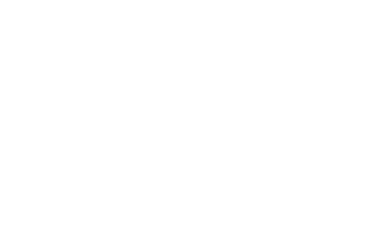

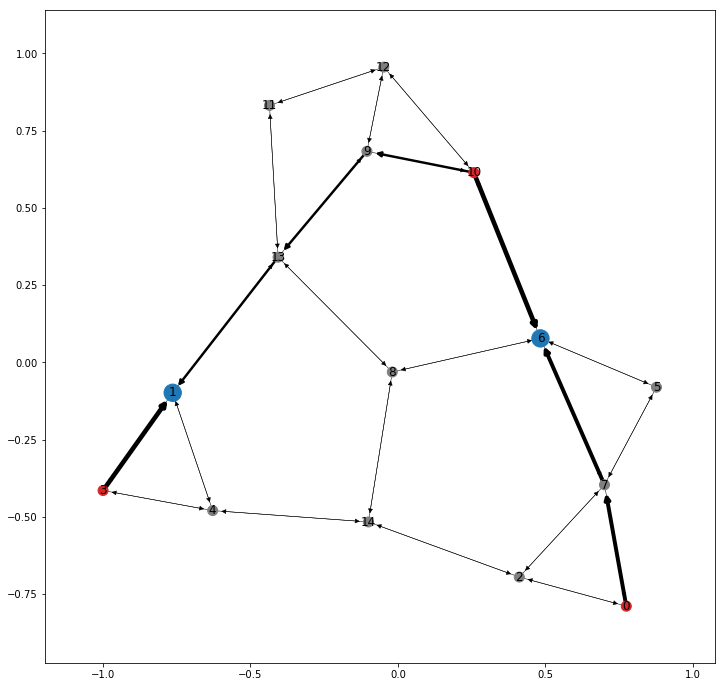

In [7]:
from heuristic_ES import heuristic_ES_solve
from networkx.readwrite.gml import read_gml
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pickle

graph_path, service_path = 'data/atlanta/atlanta.gml', 'data/atlanta/a_02.pkl'

G = read_gml(graph_path)
G = nx.relabel.relabel_nodes(G, {node : int(node) for node in G.nodes()})
with open(service_path, 'rb') as f:
    services = pickle.load(f)
    
i = len(services)

x, y, p, t, solved = heuristic_ES_solve(graph_name = graph_path, 
                                        services_name = service_path, 
                                        numb = 35, 
                                        n_selection = 30, 
                                        max_iter = 100)

print(sum(p)*int(solved))

pos = nx.drawing.layout.spring_layout(G)
weights = np.log(3*np.dot(x.transpose(), p)+1)+0.5
size = 200*np.sum(y, axis = 0)+100
origins = [demand['origin'] for service in services for demand in service]
colors = ['tab:gray']*len(G.nodes)
for origin in origins:
    colors[origin] = 'tab:red'
    
used_servers = np.sum(y, axis = 0)
# print(used_servers)
for index, server in enumerate(used_servers):
    if server and colors[index]=='tab:red':
        colors[index] = 'tab:purple'
    elif server and colors[index]=='tab:gray':
        colors[index] = 'tab:blue'

plt.axis('off')
plt.figure(3, figsize=(12,12))
nx.draw_networkx_nodes(G, pos, node_color = colors, node_size = size)
nx.draw_networkx_edges(G, 
                       pos,
                       connectionstyle="arc3,rad=0.1", 
                       width=weights)
nx.draw_networkx_labels(G, pos, labels = {i : i for i in range(len(G.nodes))})
plt.show()

Noeud gris : ressources inutilisées\
Noeuds rouges : origine des demandes\
Noeud Bleus : noeud où sont placés les services\
Noeud violets : origine et destination à la fois

Epaisseur du trait variable en fonction de l'utilisation

### ILP solver

('arc_ILP', {'Lower bound: ': '65.0', 'Termination condition: ': 'optimal', 'Upper bound: ': '65.0', 'Time: ': '1.14'})


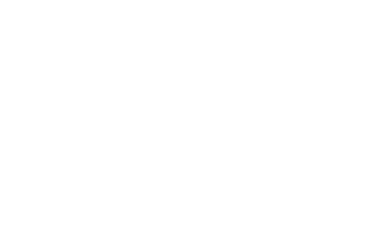

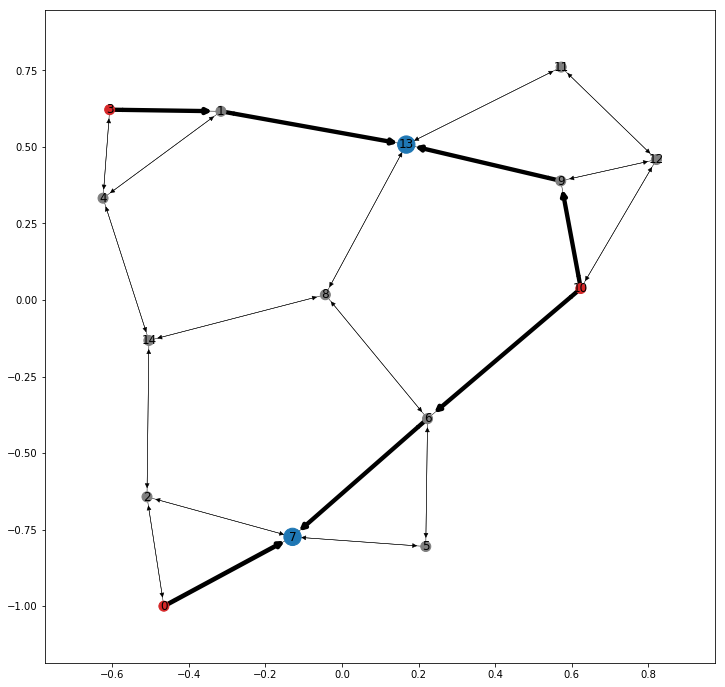

In [4]:
from arc_ILP import arc_ILP_solve

model, results = arc_ILP_solve(graph_name = graph_path, 
                  services_name = service_path, 
                  solver = 'cplex', 
                  options = {'threads' : 1, 'timelimit' : 3600})
                    
print('arc_ILP', results)

def get_array_from_model_variable(variable, shape):
    var = variable.get_values()
    arr = np.zeros(shape)
    for elem in var.keys():
        arr[elem] = var[elem]
    return arr

x = get_array_from_model_variable(model.x, (i**2, len(G.edges)))
y = get_array_from_model_variable(model.y, (i, len(G.nodes)))
p = get_array_from_model_variable(model.p, i**2)

pos = nx.drawing.layout.spring_layout(G)
weights = np.log(3*np.dot(x.transpose(), p)+1)+0.5
size = 200*np.sum(y, axis = 0)+100
origins = [demand['origin'] for service in services for demand in service]
colors = ['tab:gray']*len(G.nodes)
for origin in origins:
    colors[origin] = 'tab:red'
    
used_servers = np.sum(y, axis = 0)
# print(used_servers)
for index, server in enumerate(used_servers):
    if server and colors[index]=='tab:red':
        colors[index] = 'tab:purple'
    elif server and colors[index]=='tab:gray':
        colors[index] = 'tab:blue'
    
plt.axis('off')
plt.figure(3, figsize=(12,12))
nx.draw_networkx_nodes(G, pos, node_color = colors, node_size = size)
nx.draw_networkx_edges(G, 
                       pos,
                       connectionstyle="arc3,rad=0.1", 
                       width=weights)
nx.draw_networkx_labels(G, pos, labels = {i : i for i in range(len(G.nodes))})
plt.show()

Noeud gris : ressources inutilisées\
Noeuds rouges : origine des demandes\
Noeud Bleus : noeud où sont placés les services\
Noeud violets : origine et destination à la fois

Epaisseur du trait variable en fonction de l'utilisation

## Complete graph with heuristic solver

216


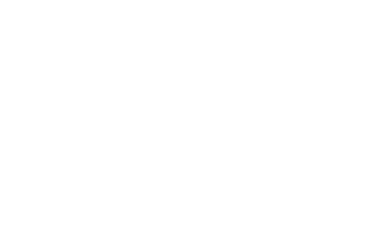

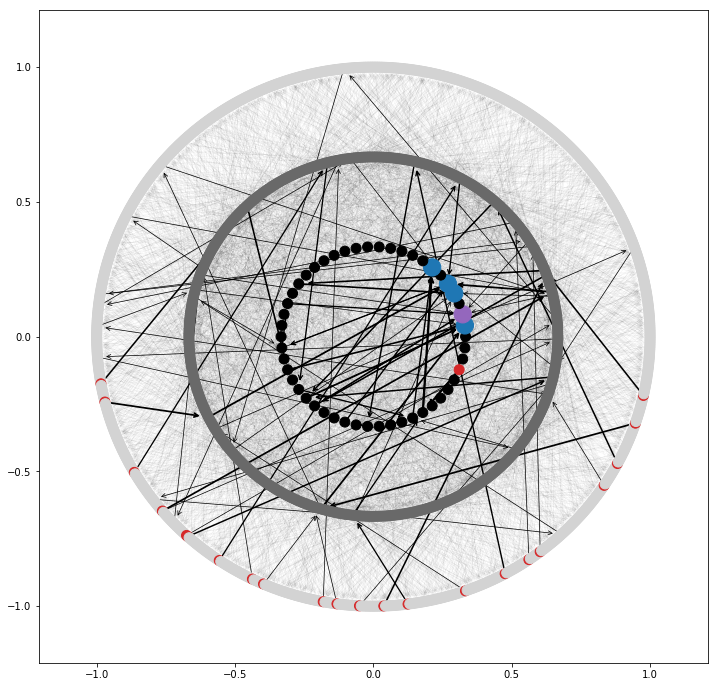

In [5]:
from heuristic_ES import heuristic_ES_solve
from networkx.readwrite.gml import read_gml
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pickle

graph_path, service_path = 'data/germany_completed/germany_completed.gml', 'data/germany_completed/g_05.pkl'

G = read_gml(graph_path)
G = nx.relabel.relabel_nodes(G, {node : int(node) for node in G.nodes()})
with open(service_path, 'rb') as f:
    services = pickle.load(f)
    
i = len(services)

x, y, p, t, solved = heuristic_ES_solve(graph_name = graph_path, 
                                        services_name = service_path, 
                                        numb = 10, 
                                        n_selection = 5, 
                                        max_iter = 10)

print(sum(p)*int(solved))

weights = 0.5*np.log(3*np.dot(x.transpose(), p)+1)+0.01
size = 200*np.sum(y, axis = 0)+100
origins = [demand['origin'] for service in services for demand in service]
colors = ['tab:gray']*len(G.nodes)
for origin in origins:
    colors[origin] = 'tab:red'
    
used_servers = np.sum(y, axis = 0)

for index, server in enumerate(used_servers):
    if server and colors[index]=='tab:red':
        colors[index] = 'tab:purple'
    elif server and colors[index]=='tab:gray':
        colors[index] = 'tab:blue'

n = len(G.nodes)//31
for index in range(len(G.edges)):
    if index < n and colors[index] == 'tab:gray':
        colors[index] = 'black'
    elif n <= index < 11*n and colors[index] == 'tab:gray':
        colors[index] = 'dimgray'
    elif 11*n <= index < 31*n and colors[index] == 'tab:gray':
        colors[index] = 'lightgray'
        
pos = nx.shell_layout(G, [range(n), range(n, 11*n), range(11*n, 31*n)])

plt.axis('off')
plt.figure(3, figsize=(12,12))
nx.draw_networkx_nodes(G, pos, node_color = colors, node_size = size)
nx.draw_networkx_edges(G, 
                       pos,
                       connectionstyle="arc3,rad=0.1", 
                       width=weights, 
                       arrowstyle='->')
 
plt.show()

Why don't the requests take a direct path to the edges servers?

Answer: for two reasons: firstly, because there are unused arcs, and instead of taking a direct path twice, they take two different paths, one of which is indirect, and secondly, because the services are uncorrectly built : in a warehouse, the users are linked to the same cloud server, and here the services don't concern the users of the same zone, but random users.

Grey node : unused resources

Red nodes: origin of the requests

Blue nodes: node where services are placed

Purple nodes: origin and destination at the same time

Thickness of the line varies according to the use